# Session 0 — From text to probabilities

The basic course used a language model as a box: text goes in, a probability for the next word comes out, and Session 11 gave a first look at the attention inside. This course opens the box. This first session covers the two ends, what goes in (tokens) and what comes out (probabilities), using a real model, GPT-2 small, which we reuse in Sessions 1 to 4.

**By the end of the session you should be able to:**

1. explain how a byte-pair-encoding (BPE) tokenizer builds its vocabulary, and why the same sentence costs a different number of tokens in different languages;
2. read a language model's output as a probability distribution and measure what each token costs in bits;
3. say why perplexity per token cannot be compared across tokenizers, and why one forward pass can score a whole text but cannot generate one.

**To run it yourself** you need `numpy`, `pandas`, `matplotlib`, `torch` and `transformers`. The first run downloads GPT-2 (about 500 MB). The outputs are already saved in the notebook. It takes about half a minute on a GPU or a laptop CPU, and numbers in the later cells may differ in the last digit on another machine.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from collections import Counter
from aij_common import DEVICE, set_seed, load_gpt2
set_seed(0)
tok, model = load_gpt2()
print(f"GPT-2 small: {sum(p.numel() for p in model.parameters())/1e6:.0f}M parameters on {DEVICE}; vocabulary {tok.vocab_size}")

GPT-2 small: 124M parameters on cuda; vocabulary 50257


The next cell holds small helper functions: one returns the model's scores for every position in a text, one turns them into bits per token, and one shows a token's raw bytes. Presenters skip it on screen. You can read it afterwards.

In [2]:
def bytes_to_unicode():
    """GPT-2's table that gives every byte a printable character."""
    bs = list(range(33, 127)) + list(range(161, 173)) + list(range(174, 256)); cs = bs[:]; n = 0
    for b in range(256):
        if b not in bs: bs.append(b); cs.append(256 + n); n += 1
    return dict(zip(bs, map(chr, cs)))

@torch.no_grad()
def logits_for(text, bos=True):
    """Logits for every position. GPT-2 has no start token, so we prepend <|endoftext|> to give the first word a context."""
    ids = tok(text)["input_ids"]
    if bos: ids = [tok.eos_token_id] + ids
    ids = torch.tensor([ids], device=DEVICE)
    return ids[0].cpu(), model(ids).logits[0].float().cpu()

def surprisal_bits(text):
    """Bits the model needs for each token of `text`, given everything before it."""
    ids, lg = logits_for(text)
    logp = lg[:-1].log_softmax(-1).gather(1, ids[1:, None])[:, 0]
    return [tok.decode(i) for i in ids[1:]], (-logp / np.log(2)).numpy()

## 1. What the model reads

GPT-2 does not read letters or words. It reads **tokens**: pieces of text from a fixed vocabulary of 50,257 entries. Each piece is turned into an integer, and the integers are all the model ever sees.

The cell below splits a few strings. Each piece is printed as the model would see it.

In [3]:
for s in ["The battery is empty.", "battery", " battery", "Battery", "unbelievably", "1234567", "3.14159", "def f(x): return x**2"]:
    pieces = [tok.decode(i) for i in tok(s)["input_ids"]]
    print(f"{s!r:28} {len(pieces)} tokens  {pieces}")

'The battery is empty.'      5 tokens  ['The', ' battery', ' is', ' empty', '.']
'battery'                    2 tokens  ['b', 'attery']
' battery'                   1 tokens  [' battery']
'Battery'                    1 tokens  ['Battery']
'unbelievably'               4 tokens  ['un', 'bel', 'iev', 'ably']
'1234567'                    3 tokens  ['123', '45', '67']
'3.14159'                    4 tokens  ['3', '.', '14', '159']
'def f(x): return x**2'      9 tokens  ['def', ' f', '(', 'x', '):', ' return', ' x', '**', '2']


Four things show up.

- **The space belongs to the word.** `' battery'` with a space is a single token, but `'battery'` at the start of a string is split into `'b'` and `'attery'`. Capitalised `'Battery'` is a different token again.
- **Rare words split into pieces.** `unbelievably` becomes four tokens (`un`, `bel`, `iev`, `ably`).
- **Numbers split arbitrarily.** `1234567` becomes `123`, `45`, `67`, and `3.14159` becomes four tokens. The model has no digit-by-digit view of a number. This is one reason arithmetic is hard for language models.
- **Code splits into short fragments** (nine tokens for `def f(x): return x**2`).

> **Pause:** four sentences of about the same length, one each in English, French, Arabic and Python. Which will need the most tokens, and how many times more than English?

In [4]:
samples = {
    "English": "The battery is empty, so the robot stopped working.",
    "French": "La batterie est vide, donc le robot a cessé de fonctionner.",
    "Arabic": "البطارية فارغة، لذلك توقف الروبوت عن العمل.",
    "Python": "def stop(robot):\n    if robot.battery == 0:\n        robot.halt()",
}
rows = []
for name, s in samples.items():
    n = len(tok(s)["input_ids"]); rows.append({"text": name, "characters": len(s), "bytes": len(s.encode()), "tokens": n, "characters_per_token": round(len(s)/n, 2)})
display(pd.DataFrame(rows))
unicode_to_byte = {u: b for b, u in bytes_to_unicode().items()}
def token_bytes(token_id):
    """GPT-2 stores each token as raw bytes; this shows them in hex."""
    return bytes(unicode_to_byte[c] for c in tok.convert_ids_to_tokens(token_id)).hex(" ")
print([token_bytes(i) for i in tok(samples["Arabic"])["input_ids"][:10]])

,text,characters,bytes,tokens,characters_per_token
0,English,51,51,11,4.64
1,French,59,60,19,3.11
2,Arabic,43,79,45,0.96
3,Python,64,64,31,2.06


['d8 a7 d9 84', 'd8 a8', 'd8', 'b7', 'd8 a7', 'd8 b1', 'd9 8a', 'd8 a9', '20 d9', '81']


English needs 11 tokens for 51 characters, which is 4.6 characters per token. French needs 19 tokens (3.1 per token). Python needs 31 (2.1 per token). Arabic needs 45 tokens for 43 characters, so less than one character per token, and about four times as many tokens as English for the same meaning.

The reason is in the bytes. The tokenizer works on UTF-8 bytes, and each Arabic letter takes two bytes (79 bytes for 43 characters). The vocabulary has a few Arabic pieces, such as the two-letter token `d8 a7 d9 84` (the letters ال), and `d8 a8` for the letter ب. For other letters the tokenizer falls back to single bytes. The letter ط is split across two tokens, `d8` and `b7`, with neither one meaningful alone.

A model can handle any text, since every string can be written in bytes and no `<unk>` token is needed. The price is that some languages pay several times more tokens, which means more computation per sentence, a shorter effective context window, and a higher bill on a per-token API.

## 2. Where the vocabulary comes from

GPT-2's vocabulary was **learned** with byte-pair encoding. The recipe is short.

1. Start with every word written as single characters (here with an end-of-word marker `</w>`).
2. Count every pair of neighbouring symbols across the corpus.
3. Merge the most frequent pair into a new symbol, and repeat.

The cell runs eight merges on a tiny corpus of word families (`low`, `lowest`, `newer`, `wide` and so on).

In [5]:
corpus = "the lower the lowest low lowly newer newest new wider widest wide " * 3
words = Counter(corpus.split())
vocab = {tuple(w) + ("</w>",): c for w, c in words.items()}

def most_frequent_pair(vocab):
    pairs = Counter()
    for word, c in vocab.items():
        for a, b in zip(word[:-1], word[1:]): pairs[(a, b)] += c
    return pairs.most_common(1)[0]

def merge(vocab, pair):
    out = {}
    for word, c in vocab.items():
        new, i = [], 0
        while i < len(word):
            if i < len(word) - 1 and (word[i], word[i+1]) == pair: new.append(word[i] + word[i+1]); i += 2
            else: new.append(word[i]); i += 1
        out[tuple(new)] = c
    return out

merges = []
for step in range(8):
    pair, count = most_frequent_pair(vocab)
    merges.append((pair, count)); vocab = merge(vocab, pair)
    print(f"merge {step+1:2d}: {pair[0]!r} + {pair[1]!r}  (seen {count} times)")
print(list(vocab))

merge  1: 'l' + 'o'  (seen 12 times)
merge  2: 'lo' + 'w'  (seen 12 times)
merge  3: 'e' + '</w>'  (seen 9 times)
merge  4: 'e' + 'r'  (seen 9 times)
merge  5: 'er' + '</w>'  (seen 9 times)
merge  6: 'e' + 's'  (seen 9 times)
merge  7: 'es' + 't'  (seen 9 times)
merge  8: 'est' + '</w>'  (seen 9 times)
[('t', 'h', 'e</w>'), ('low', 'er</w>'), ('low', 'est</w>'), ('low', '</w>'), ('low', 'l', 'y', '</w>'), ('n', 'e', 'w', 'er</w>'), ('n', 'e', 'w', 'est</w>'), ('n', 'e', 'w', '</w>'), ('w', 'i', 'd', 'er</w>'), ('w', 'i', 'd', 'est</w>'), ('w', 'i', 'd', 'e</w>')]


In [6]:
from huggingface_hub import hf_hub_download
merge_ranks = open(hf_hub_download("gpt2", "merges.txt")).read().splitlines()[1:]
print(len(merge_ranks), "merges in GPT-2")
print("first 8:", merge_ranks[:8])
print("last 5:", merge_ranks[-5:])

50000 merges in GPT-2
first 8: ['Ġ t', 'Ġ a', 'h e', 'i n', 'r e', 'o n', 'Ġt he', 'e r']
last 5: ['om inated', 'Ġreg ress', 'ĠColl ider', 'Ġinform ants', 'Ġg azed']


The first merge is `l`+`o` and the second `lo`+`w`, so `low` becomes one symbol after two steps. Then the endings appear: `e</w>`, `er</w>`, `est</w>`. A word seen in many forms has its stem and its endings stored as separate pieces. After 8 merges `lowest` is `low` + `est</w>`, and `widest` is `w`, `i`, `d` + `est</w>`: the letters `w`, `i`, `d` have not been merged yet.

GPT-2 did the same on a large web corpus and stopped after 50,000 merges. The 50,257 vocabulary entries are the 256 byte values, those 50,000 merges, and one special token, `<|endoftext|>`. The second cell prints GPT-2's own merge list. The earliest merges are the most common pairs (`Ġ t`, `Ġ a`, `h e`, where `Ġ` marks a leading space), and the last ones are rare words such as `Ġinform ants` and `Ġg azed`.

Tokenisation is fixed before training. The model never sees the pair counts, and a poor vocabulary for your language or domain cannot be fixed afterwards without retraining.

## 3. From ids to vectors

The first layer of the model is a table with one row per token id. Looking up a token means reading its row.

In [7]:
E = model.transformer.wte.weight.detach().float().cpu()
print("embedding table:", tuple(E.shape), "=", E.numel()/1e6, "M parameters,", f"{100*E.numel()/sum(p.numel() for p in model.parameters()):.0f}% of the model")
def neighbours(word, k=8):
    i = tok(word)["input_ids"]; assert len(i) == 1, i
    v = torch.nn.functional.normalize(E, dim=1); sims = v @ v[i[0]]
    top = sims.topk(k + 1)
    return [(tok.decode(j), round(s.item(), 2)) for s, j in zip(top.values[1:], top.indices[1:])]
for w in [" battery", " empty", " robot"]: print(w, "->", neighbours(w))

embedding table: (50257, 768) = 38.597376 M parameters, 31% of the model
 battery -> [(' Battery', 0.8), (' batteries', 0.8), ('Battery', 0.73), (' lithium', 0.56), ('attery', 0.52), (' charger', 0.49), (' electrode', 0.47), (' voltage', 0.46)]


 empty -> [('empty', 0.75), (' Empty', 0.72), ('Empty', 0.67), (' emptied', 0.62), (' emptiness', 0.58), (' vacant', 0.58), (' empt', 0.52), (' blank', 0.52)]
 robot -> [(' robots', 0.81), (' robotic', 0.74), (' Robot', 0.7), (' robotics', 0.65), (' Robots', 0.64), (' bots', 0.58), ('Rob', 0.54), (' Robotics', 0.54)]


The table has 50,257 rows of 768 numbers, which is 38.6 million parameters and 31% of the whole model. The rows were learned like any other weights, and nearby rows are tokens used in similar ways. The nearest neighbours of ` battery` by cosine similarity are ` Battery` and ` batteries` (0.80 each), then `Battery` (0.73), ` lithium` (0.56), ` charger` (0.49) and ` voltage` (0.46). The neighbours of ` robot` are ` robots` (0.81) and ` robotic` (0.74).

Two things to notice. Case and plural forms of the same word are separate rows, and they are close because they appear in similar contexts. And the vector holds no meaning on its own. Everything a model knows about a word in a sentence comes from the layers that read these rows, which are the subject of the next two sessions.

## 4. From vectors to probabilities

The model's last layer produces one score (a **logit**) for every token in the vocabulary, at every position. A softmax turns the scores at a position into probabilities for the next token. We feed it `The battery is empty.`. GPT-2 has no start token, so we put `<|endoftext|>` in front, which gives the first word something to follow.

In [8]:
ids, lg = logits_for("The battery is empty.")
print("input ids:", ids.tolist()); print("logits shape:", tuple(lg.shape), "(one row of", lg.shape[1], "scores per position)")
p = lg[-1].softmax(-1); top = p.topk(10)
display(pd.DataFrame({"next token": [repr(tok.decode(i)) for i in top.indices], "probability": top.values.numpy().round(3)}))
print("entropy of this distribution:", round(-(p * p.log()).sum().item() / np.log(2), 2), "bits;", "mass on top 10:", round(top.values.sum().item(), 2))

input ids: [50256, 464, 6555, 318, 6565, 13]
logits shape: (6, 50257) (one row of 50257 scores per position)


,next token,probability
0,'\n',0.247
1,' The',0.138
2,' It',0.055
3,' I',0.034
4,' You',0.026
5,'\n\n',0.017
6,' There',0.015
7,' We',0.014
8,' A',0.013
9,' No',0.012


entropy of this distribution: 6.52 bits; mass on top 10: 0.57


The input is 6 ids, and the output is a 6 × 50,257 table: at each position, a score for every possible next token. We read the last row. After `The battery is empty.` the most likely next token is a newline (0.247), then ` The` (0.138), ` It` (0.055) and ` I` (0.034). The top ten tokens hold 0.57 of the probability. The entropy of the whole distribution is 6.5 bits, as uncertain as choosing among about 90 equally likely tokens.

Next, how surprised is the model by a real sentence? For each token we take the probability the model gave it, and report $-\log_2 p$ in bits.

> **Pause:** which tokens of *The battery is empty, so the robot stopped working and waited beside the charger.* will cost the most bits, and which the fewest?

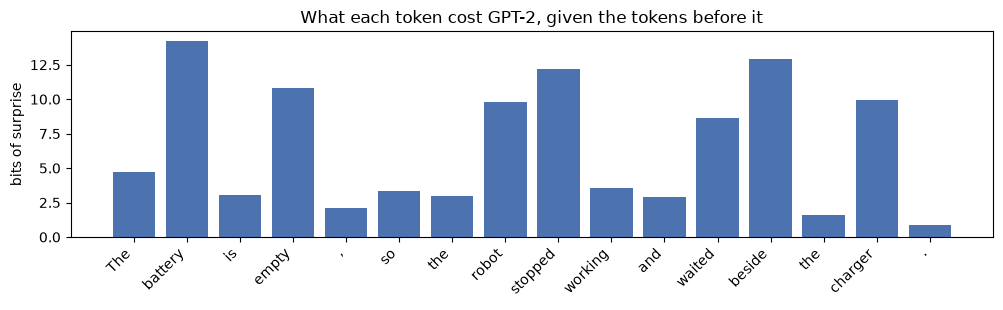

total 103.7 bits over 16 tokens: mean 6.48 bits/token, perplexity 89.5
highest: [(' battery', 14.2), (' beside', 12.9), (' stopped', 12.2), (' empty', 10.8)]
lowest: [(',', 2.1), (' the', 1.6), ('.', 0.9)]


In [9]:
text = "The battery is empty, so the robot stopped working and waited beside the charger."
toks, bits = surprisal_bits(text)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(range(len(bits)), bits, color="#4c72b0"); ax.set_xticks(range(len(bits)), [repr(t)[1:-1] for t in toks], rotation=45, ha="right")
ax.set_ylabel("bits of surprise"); ax.set_title("What each token cost GPT-2, given the tokens before it"); plt.tight_layout(); plt.show()
print(f"total {bits.sum():.1f} bits over {len(bits)} tokens: mean {bits.mean():.2f} bits/token, perplexity {2**bits.mean():.1f}")
ranked = sorted(zip(toks, bits), key=lambda x: -x[1])
print("highest:", [(t, round(float(b), 1)) for t, b in ranked[:4]]); print("lowest:", [(t, round(float(b), 1)) for t, b in ranked[-3:]])

The chart shows the answer. The most expensive tokens are content words that the earlier words did not predict: ` battery` (14.2 bits, a rare word right after `The`), ` beside` (12.9), ` stopped` (12.2) and ` empty` (10.8). The cheapest are function words and punctuation that the context makes almost certain: ` the` before `charger` costs 1.6 bits and the final `.` 0.9.

The whole sentence costs 103.7 bits over 16 tokens, a mean of 6.5 bits per token. Taking $2^{6.5}$ gives a perplexity of 89.5, so on this sentence GPT-2 behaves as if choosing among about 90 equally likely tokens at each step. Training a language model means lowering this number on text it has not seen.

## 5. Why perplexity depends on the tokenizer

A common mistake is to compare perplexities of two models on the same text. The comparison only works if both use the same tokenizer. The cell below measures GPT-2 on four sentences in English, French and Arabic that say the same things, and reports the cost per token and per character.

> **Pause:** GPT-2 was trained mostly on English. Which language will have the lowest perplexity per token?

In [10]:
parallel = {
    "English": ["The battery is empty, so the robot stopped working.", "The charger is beside the robot.", "Please close the door before you leave.", "The meeting starts at nine o'clock tomorrow."],
    "French": ["La batterie est vide, donc le robot a cessé de fonctionner.", "Le chargeur est à côté du robot.", "Veuillez fermer la porte avant de partir.", "La réunion commence demain à neuf heures."],
    "Arabic": ["البطارية فارغة، لذلك توقف الروبوت عن العمل.", "الشاحن بجانب الروبوت.", "يرجى إغلاق الباب قبل المغادرة.", "يبدأ الاجتماع غدًا في الساعة التاسعة."],
}
rows = []
for name, sentences in parallel.items():
    bits = np.concatenate([surprisal_bits(s)[1] for s in sentences]); chars = sum(len(s) for s in sentences)
    rows.append({"language": name, "tokens": len(bits), "characters": chars, "total bits": round(float(bits.sum())), "bits/token": round(float(bits.mean()), 2), "perplexity (per token)": round(float(2 ** bits.mean()), 1), "bits/character": round(float(bits.sum() / chars), 2)})
display(pd.DataFrame(rows))

,language,tokens,characters,total bits,bits/token,perplexity (per token),bits/character
0,English,36,166,222,6.17,71.9,1.34
1,French,58,173,475,8.19,291.4,2.74
2,Arabic,129,131,553,4.29,19.5,4.22


By perplexity per token Arabic looks best: 19.5, against 71.9 for English and 291.4 for French. The totals show why that ranking misleads. Arabic costs 553 bits for the four sentences and English only 222, so Arabic is much harder for GPT-2. But the 553 bits are spread over 129 tokens, against 36 for English, so each Arabic token looks cheap (4.29 bits against 6.17).

Per character, which does not depend on how the text was cut up, the order flips: English costs 1.34 bits per character, French 2.74 and Arabic 4.22. That is what you would expect from a model trained mostly on English. Whenever you read a perplexity, ask what the unit was. A model with a larger vocabulary has fewer, harder tokens, and a higher perplexity per token for the same quality. Session 3 trains a model and reports bits per character for that reason.

## 6. One pass to train, one pass per token to generate

A language model is trained to predict every next token of a text. The text is fed in once, and the model returns predictions for all positions together. To generate, the model has to produce one token, append it, and run again.

The first cell generates 12 tokens greedily (always taking the most likely token) from `The battery is empty, so the robot`.

In [11]:
prompt = "The battery is empty, so the robot"
ids = torch.tensor([[tok.eos_token_id] + tok(prompt)["input_ids"]], device=DEVICE)
steps, forward_passes = [], 0
with torch.no_grad():
    for _ in range(12):
        nxt = model(ids).logits[0, -1].argmax(); forward_passes += 1
        ids = torch.cat([ids, nxt.view(1, 1)], 1); steps.append(tok.decode(nxt))
print(prompt + "".join(steps)); print("forward passes:", forward_passes)

The battery is empty, so the robot is not moving.

The robot is moving, but
forward passes: 12


In [12]:
full_ids = ids  # the finished sequence
with torch.no_grad():
    one_pass = model(full_ids).logits[0].float()
    worst = 0
    for t in range(1, full_ids.shape[1]):
        prefix = model(full_ids[:, :t]).logits[0, -1].float()
        worst = max(worst, (prefix - one_pass[t-1]).abs().max().item())
print(f"{full_ids.shape[1]} positions scored in 1 pass vs {full_ids.shape[1]-1} separate prefix passes; largest logit difference: {worst:.1e}")

21 positions scored in 1 pass vs 20 separate prefix passes; largest logit difference: 5.2e-04


It takes 12 forward passes. The output continues "is not moving" and then starts to repeat itself ("The robot is moving, but"), which is typical of greedy decoding and is the subject of Session 3.

The second cell checks something useful about training. We score the finished 21-token sequence in one pass. Then we cut the same sequence at every prefix, run the model on each prefix separately, and compare the last row of each prefix with the matching row from the single pass. The largest difference in any logit is 5.2e-04, which is rounding, so the prediction at a position depends only on the tokens before it. The causal mask in the attention layers is what guarantees this (Session 1), and it is why training can use all 21 positions of a text at the cost of a single pass.

## What to take away

- A tokenizer cuts text into pieces from a vocabulary that was learned by merging frequent pairs. The same meaning costs different numbers of tokens in different languages, and digits and rare words split into fragments.
- A language model outputs a score for each vocabulary entry at each position. A softmax makes these probabilities, and $-\log_2 p$ is the cost in bits.
- Perplexity is $2^{\text{mean bits per token}}$. It can be compared only between models that share a tokenizer. Bits per character can be compared more widely.
- Training scores all positions in one pass. Generating needs one pass per new token.

---

# Going deeper

*The rest of this notebook is for reading after the session.*

## Byte-level BPE in detail

GPT-2's tokenizer first splits text into chunks with a regular expression (words with their leading space, runs of digits, punctuation), then applies the learned merges inside each chunk. At encoding time the merges are applied in the order they were learned, always taking the earliest merge available. That is why the result is deterministic, and why ` battery` is a single token while `battery` at the start of a string is not: the merge `Ġ b` and its follow-ups exist, and the bare word has no leading space to attach to.

Other tokenizers (WordPiece in BERT, unigram language models in SentencePiece) choose the vocabulary differently, but they all trade vocabulary size against sequence length. A larger vocabulary shortens sequences and enlarges the embedding table and the output layer.

## Bits, perplexity and bits per character

For a text of $T$ tokens and $C$ characters, with the model assigning probability $p_t$ to token $t$:

$$
\text{bits per token}=-\frac{1}{T}\sum_{t}\log_2 p_t,\qquad \text{perplexity}=2^{\text{bits per token}},\qquad \text{bits per character}=\frac{T}{C}\cdot\text{bits per token}.
$$

The same total cost can be spread over many easy tokens or a few hard ones. Only the total, divided by a unit that does not depend on the tokenizer (characters, or bytes), can be compared across tokenizers.

## Tied embeddings

The output layer maps a hidden vector back to 50,257 scores. GPT-2 reuses the embedding table for this, so the score for a token is the dot product between the final hidden state and that token's embedding. The cell checks it.

In [13]:
lm_head, wte = model.lm_head.weight, model.transformer.wte.weight
print("output layer shares the embedding table:", lm_head.data_ptr() == wte.data_ptr())

output layer shares the embedding table: True


The output layer and the input table are the same tensor, so the 38.6 million embedding parameters are counted once. Tying makes sense for a small model, where the table is a third of the weights. Larger models often keep the two separate.

## Why the first token needs a start token

Without `<|endoftext|>` in front, the first real token has no context, and the model cannot score it. GPT-2 was trained on documents separated by this token, so putting it first matches how it saw text during training.